# Practice Session 08: Communities

In [1]:
# LEAVE AS-IS

import io
import networkx as nx
import matplotlib.pyplot as plt
import random
import numpy as np
import statistics

# 1. The graph

In [7]:
# LEAVE AS-IS

INPUT_GRAPH_FILENAME = "starwars.graphml"

# Read the graph in GraphML format
sw_in = nx.read_graphml(INPUT_GRAPH_FILENAME)

# Re-label the nodes so they use the 'name' as label
sw_relabeled = nx.relabel.relabel_nodes(sw_in, dict(sw_in.nodes(data='name')))

# Convert the graph to undirected
sw = sw_relabeled.to_undirected()

In [8]:
# LEAVE AS-IS (OR MODIFY VISUALLY)

def plot_graph(g, width=20, height=20, font_size=12, partition=None):

    # Create a plot of width x height
    plt.figure(figsize=(width, height))

    # By default the partition is going to be all nodes in the same partition
    if partition is None:
        partition = [ set(g.nodes()) ]

    # Number of partitions
    num_parts = len(partition)

    # Create a map from nodes to color using color values from 0.0 for the first partition
    # to 1-1/P for the last partition, assuming there are P partitions
    node_to_color = {}
    part_color = 0.0
    for part in partition:
        for node in part:
            node_to_color[node] = part_color
        part_color += 1.0/num_parts

    # Create a list of colors in the ordering of the nodes
    colors = [node_to_color[node] for node in g.nodes()]

    # Layout the nodes using a spring model
    nx.draw_spring(g, with_labels=True, node_size=1000, font_size=font_size,
                   cmap=plt.get_cmap('YlOrRd'), node_color=colors)

    # Display
    plt.show()

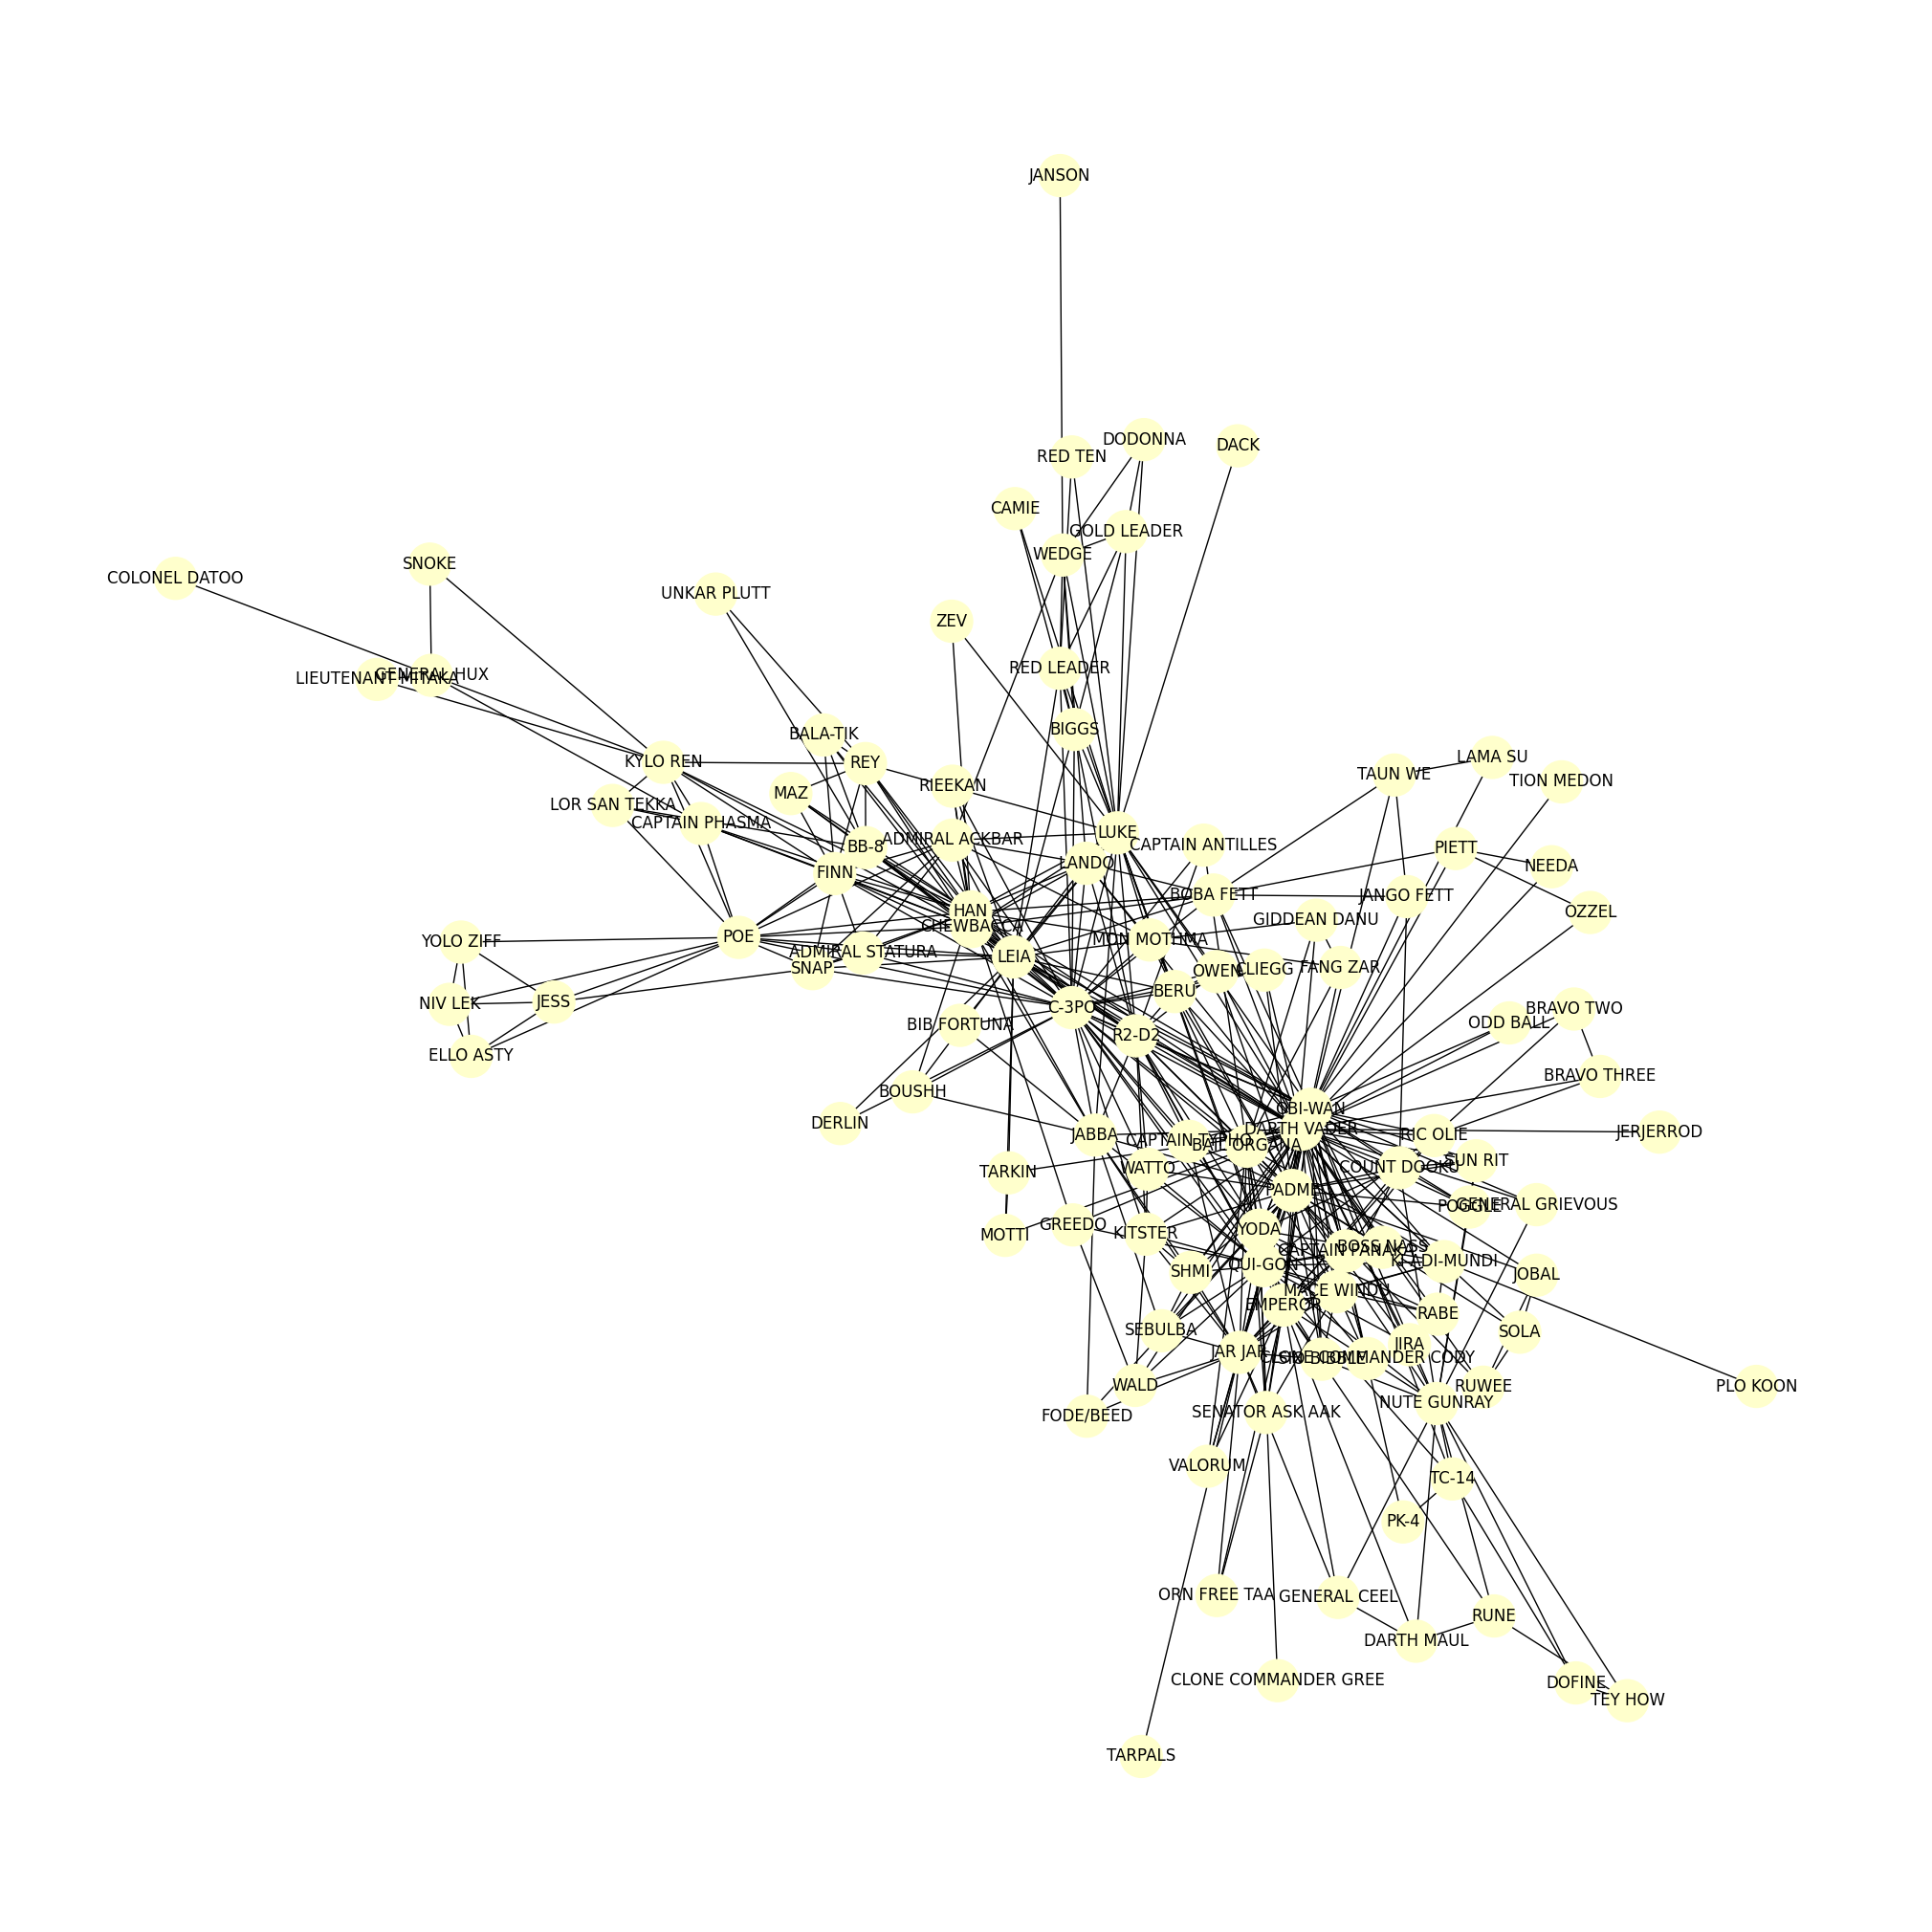

In [9]:
# LEAVE AS-IS

plot_graph(sw)

# 2. K-core decomposition

In [10]:
# LEAVE AS-IS

def get_max_degree(g):
    degree_sequence = [x[1] for x in g.degree()]
    return(max(degree_sequence))


def nodes_with_degree_less_or_equal_than(g, degree):
    nodes = []
    for node in g.nodes():
        if g.degree(node) <= degree:
            nodes.append(node)
    return nodes

In [ ]:
def kcore_decomposition(graph):
    g = graph.copy()

    max_degree = get_max_degree(g)

    node_to_level = {}

    for level in range(1, max_degree + 1):
        while True:

            nodes_in_level = nodes_with_degree_less_or_equal_than(g, level)
            if len(nodes_in_level) == 0:
                break

            for node in nodes_in_level:
                node_to_level[node] = level
                g.remove_node(node)

    return node_to_level

In [12]:
# LEAVE AS-IS

node_to_kcore = kcore_decomposition(sw)

for character in ["JANSON", "R2-D2", "LUKE", "DARTH VADER"]:
    print("K-core of {:s}: {:d}".format(character, node_to_kcore[character]))

K-core of JANSON: 1
K-core of R2-D2: 8
K-core of LUKE: 7
K-core of DARTH VADER: 8


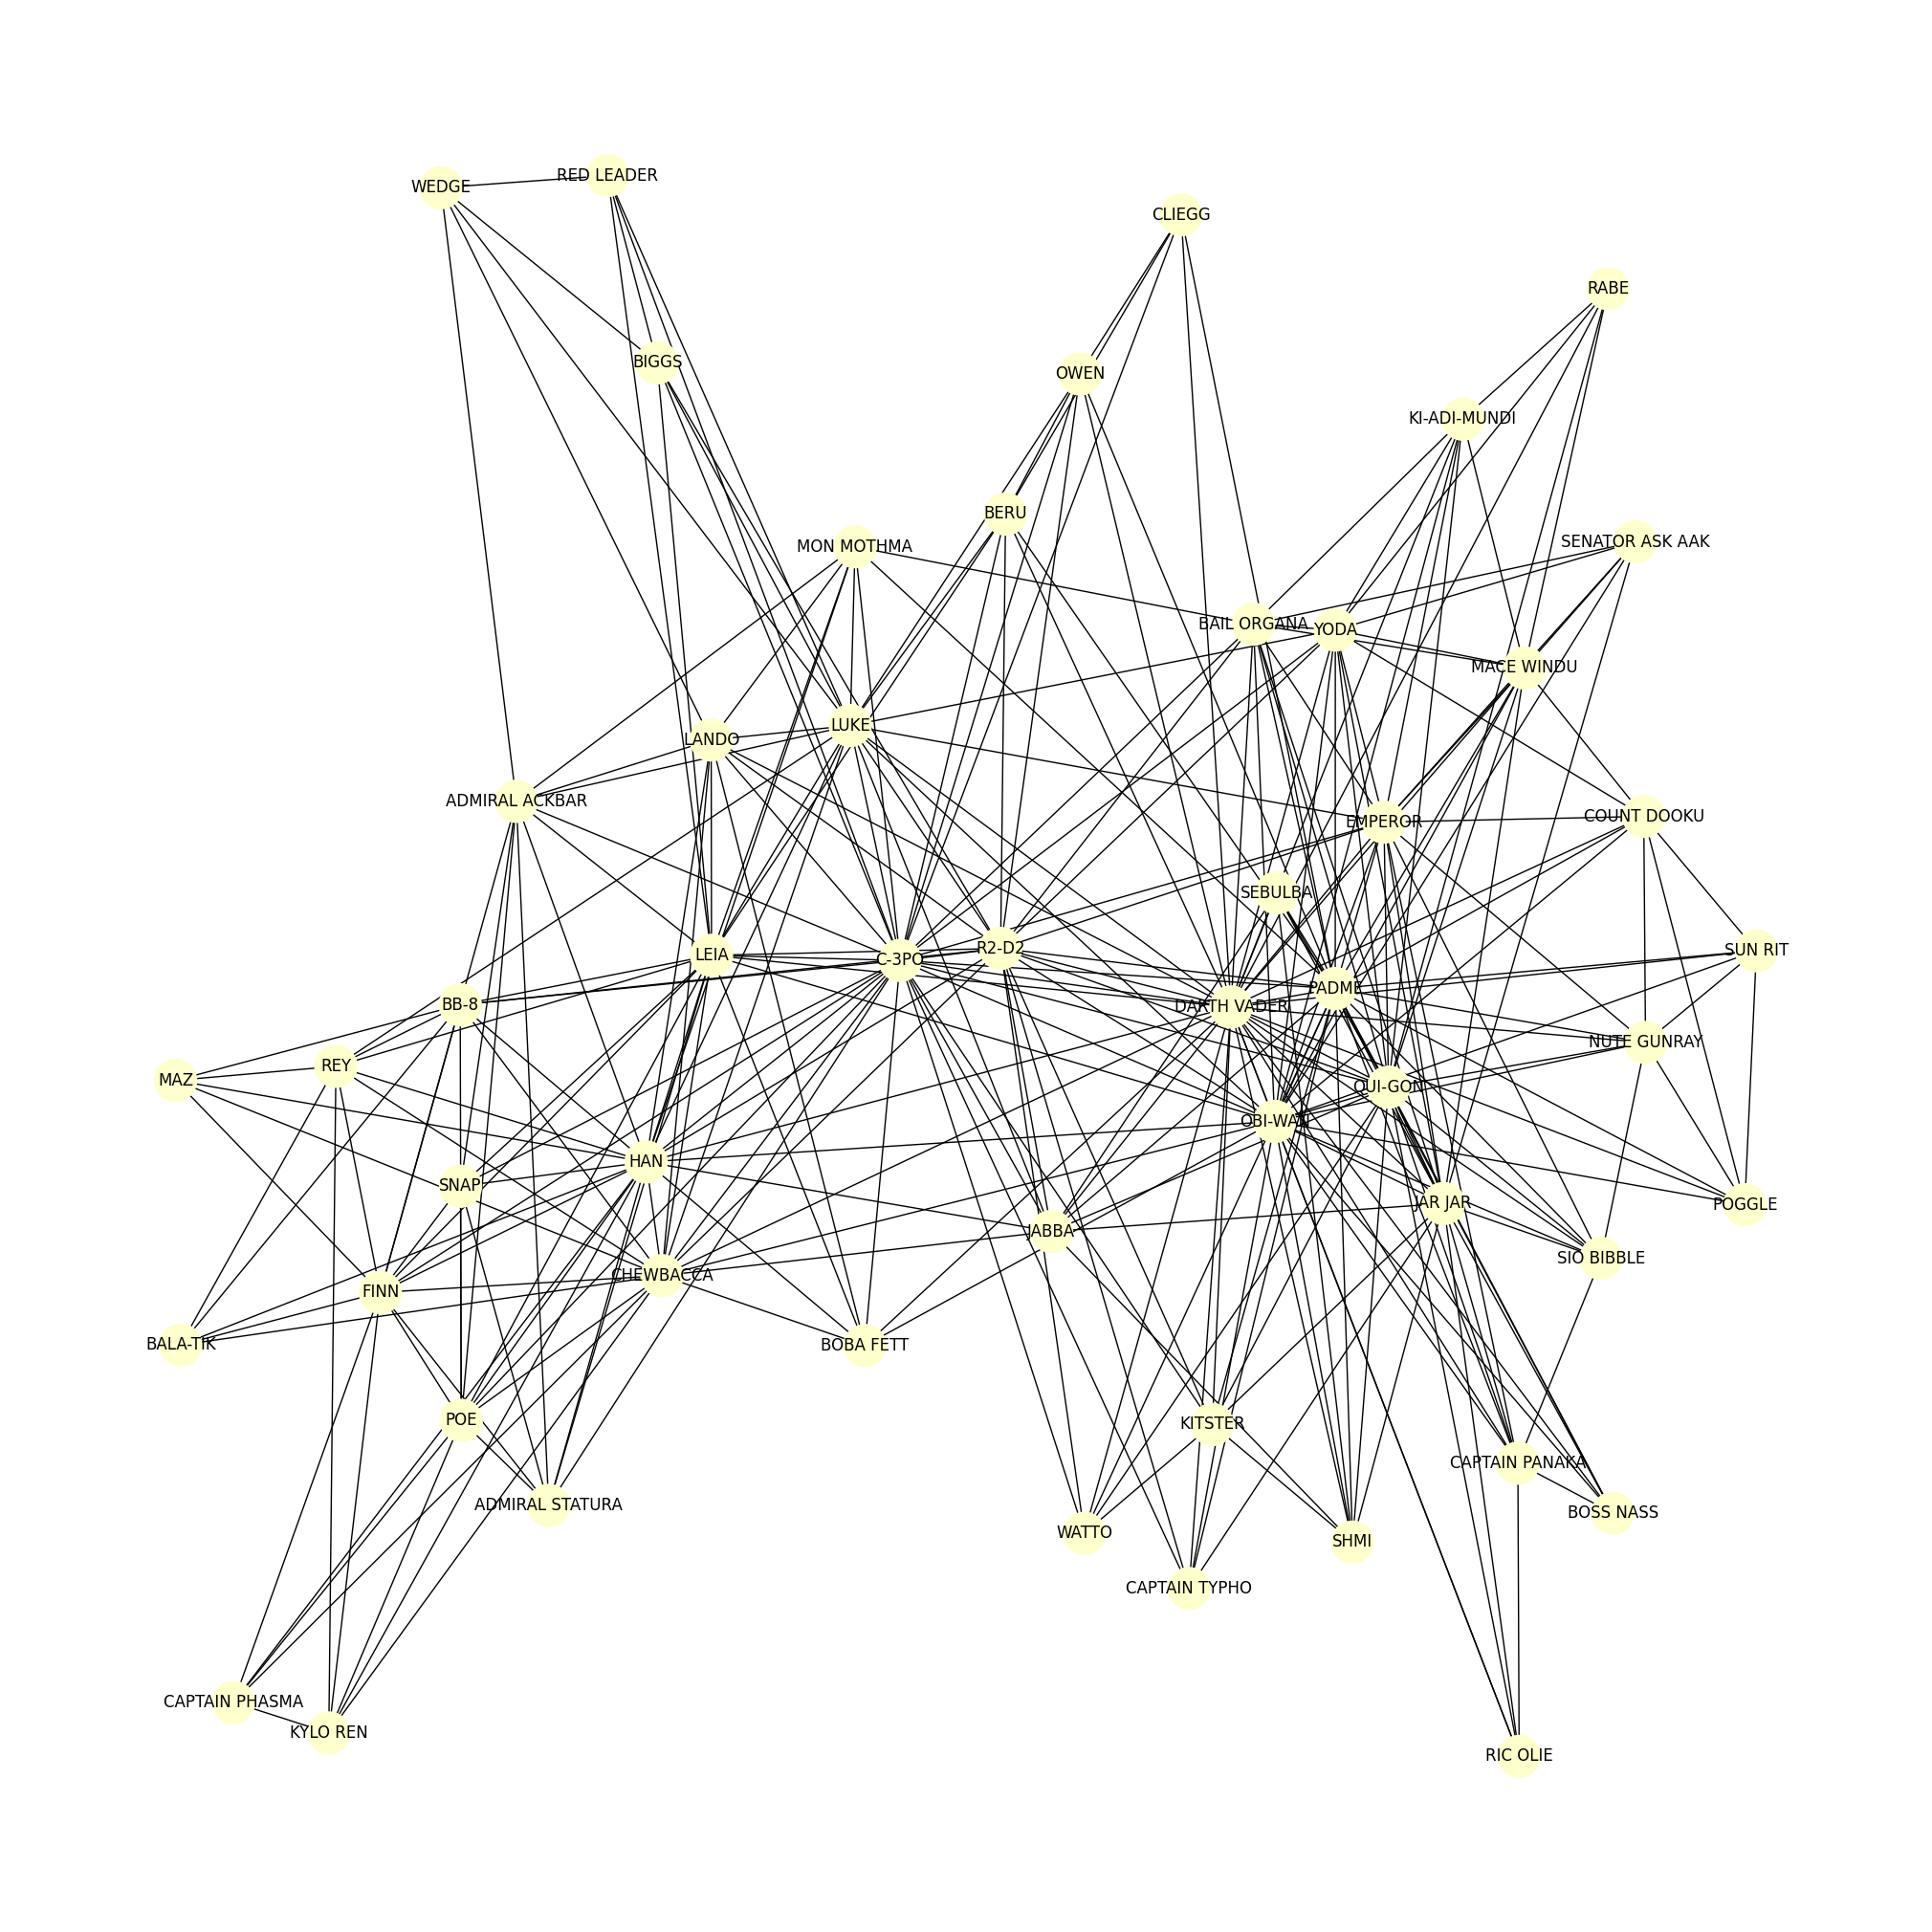

In [ ]:
core_nodes = [node for node, kcore in node_to_kcore.items() if kcore >= 5]
swcore = sw.subgraph(core_nodes)
plot_graph(swcore)

The nodes left in the graph are the most important characters in the movies because they have a higher degree than the ones that are gone. We can see this is true because some of the nodes left are the main characters in the series like Darth Vader and Obi-Wan.

# 3. Modularity of a partition

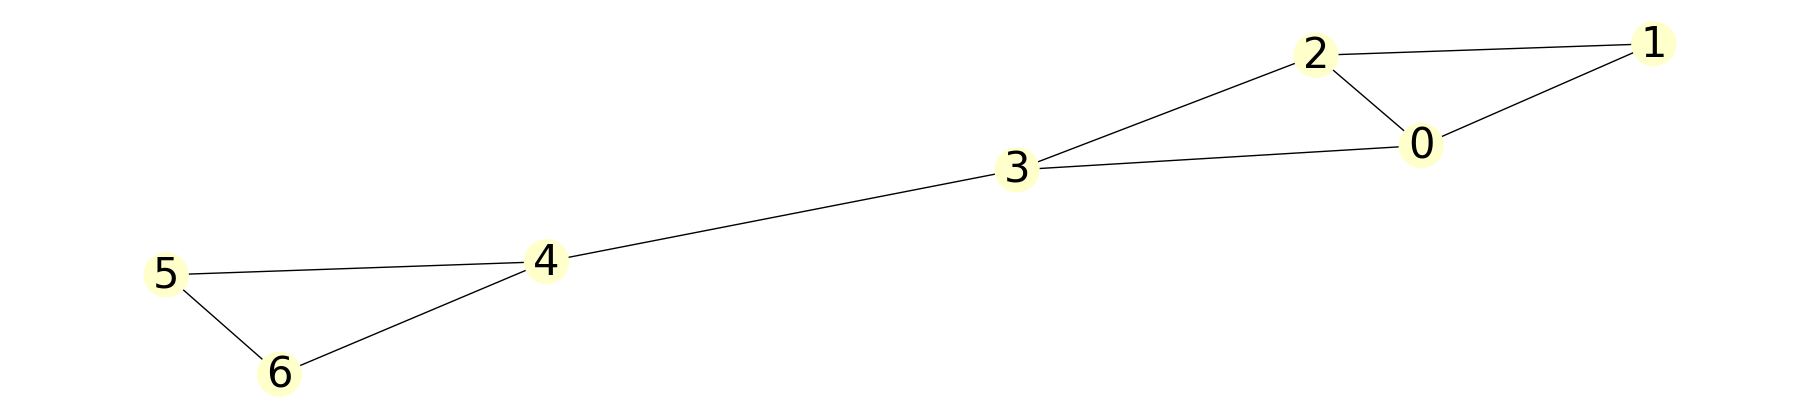

In [13]:
# Leave as-is

g = nx.Graph()

g.add_edge(0, 1)
g.add_edge(1, 2)
g.add_edge(2, 3)
g.add_edge(3, 0)
g.add_edge(0, 2)
g.add_edge(3, 4)
g.add_edge(4, 5)
g.add_edge(5, 6)
g.add_edge(6, 4)

# NOTE: for each run, the visualization will be different, but the graph should have the connections indicated above
plot_graph(g, height=4, width=18, font_size=30)

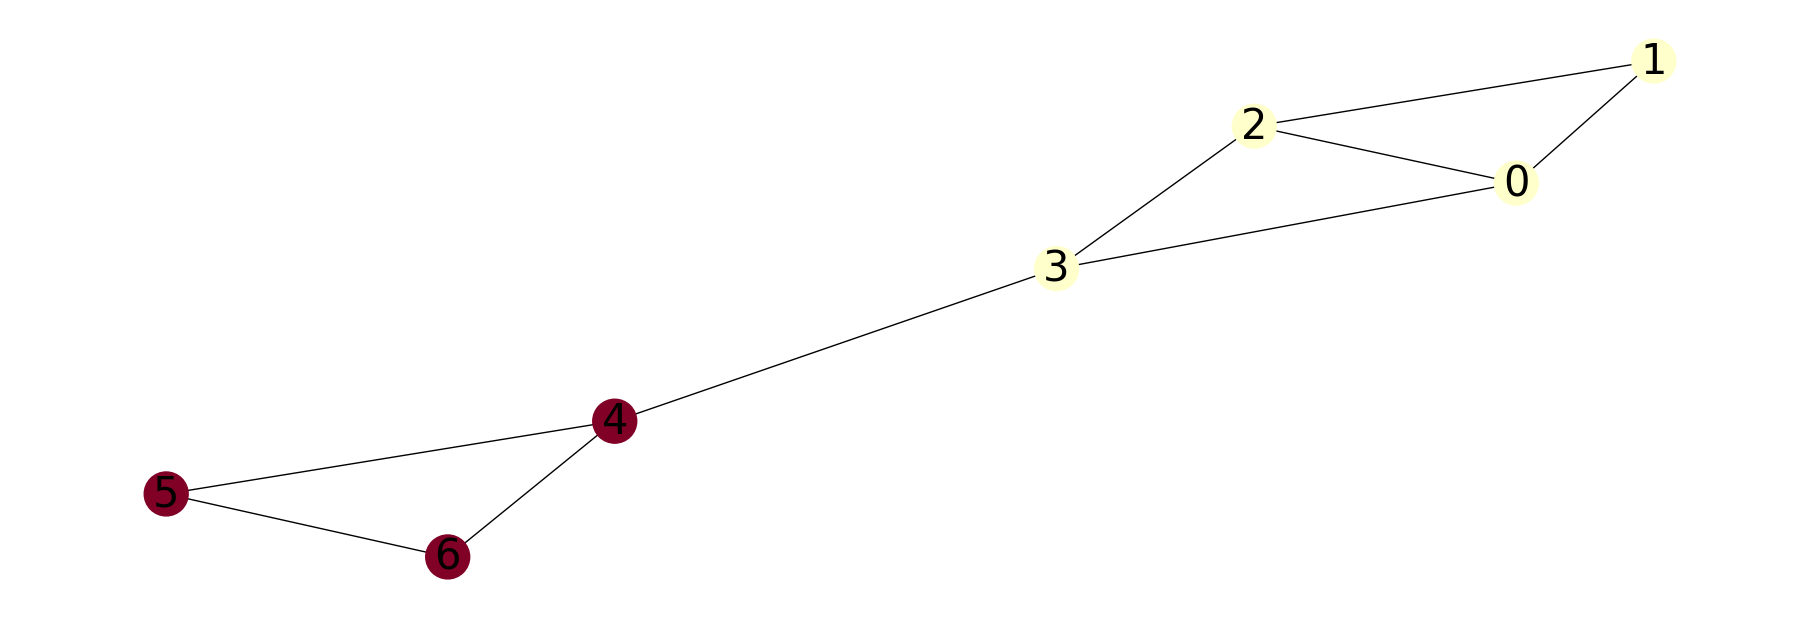

Modularity of partition 1 according to NetworkX: 0.3642


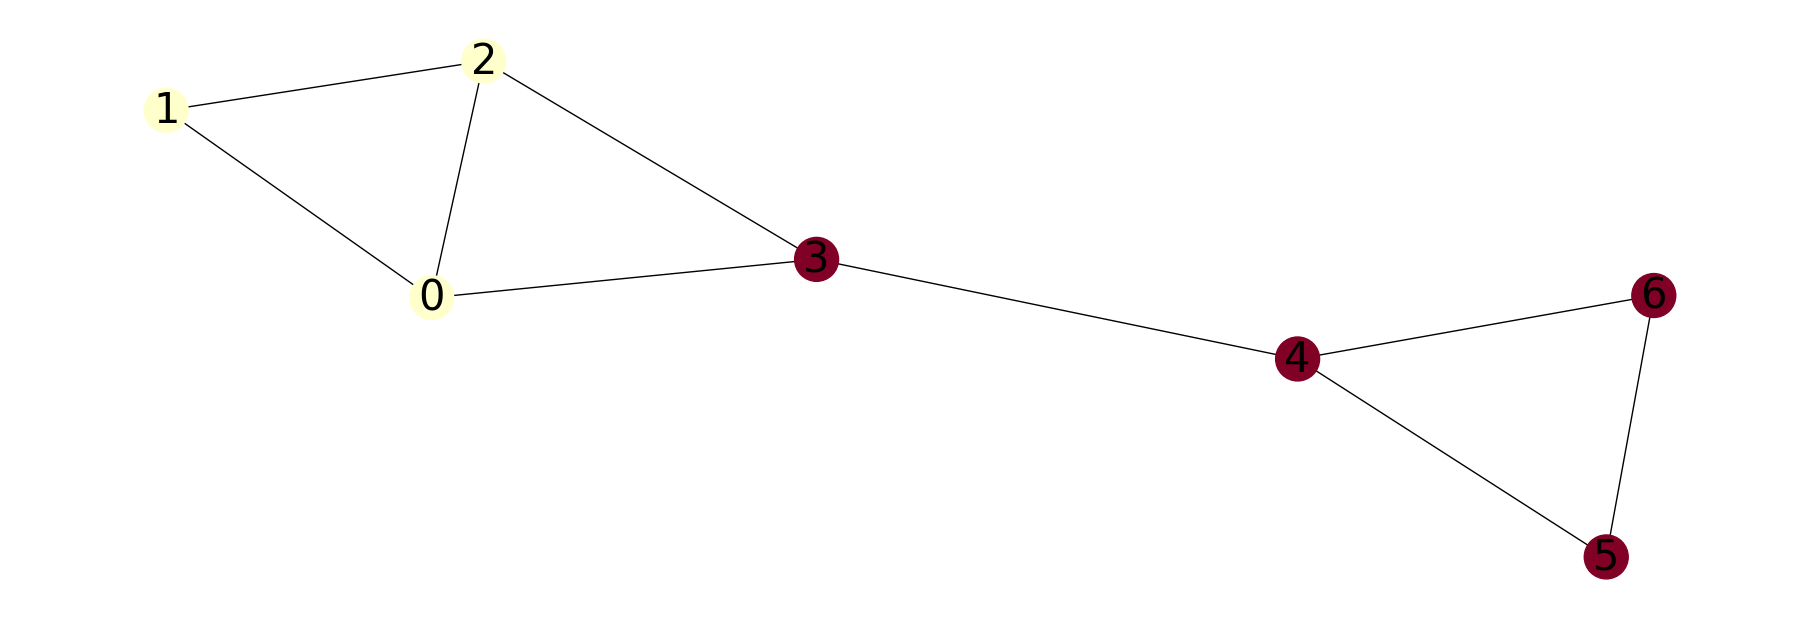

Modularity of partition 2 according to NetworkX: 0.2716


In [14]:
# LEAVE AS-IS

partition1 = [
    {0, 1, 2, 3},
    {4, 5, 6}
]
plot_graph(g, height=6, width=18, font_size=30, partition=partition1)
print("Modularity of partition 1 according to NetworkX: %.4f" % nx.community.quality.modularity(g, partition1))


partition2 = [
    {0, 1, 2},
    {3, 4, 5, 6}
]
plot_graph(g, height=6, width=18, font_size=30, partition=partition2)
print("Modularity of partition 2 according to NetworkX: %.4f" % nx.community.quality.modularity(g, partition2))

In [29]:
def Lc(g, C):
    subgraph = g.subgraph(C)
    return subgraph.number_of_edges()

def kc(g, C):
    return sum(dict(g.degree(C)).values())

def modularity(g, partition):
    L = g.number_of_edges()
    Q = 0.0
    for C in partition:
        L_C = Lc(g, C)
        k_C = kc(g, C)
        Q += (L_C / L) - (k_C / (2 * L)) ** 2
    return Q

In [16]:
# LEAVE AS-IS

print("Modularity of partition 1: mine={:.6f}, networkx={:.6f}".format(
    modularity(g, partition1), nx.community.quality.modularity(g, partition1)))

print("Modularity of partition 2: mine={:.6f}, networkx={:.6f}".format(
    modularity(g, partition2), nx.community.quality.modularity(g, partition2)))


Modularity of partition 1: mine=0.364198, networkx=0.364198
Modularity of partition 2: mine=0.271605, networkx=0.271605


# 4. Girvan-Newman algorithm

## 4.1. Find the edge with the largest betweenness

In [ ]:
def largest_betweenness_edge(g):

    edge_betweenness = nx.edge_betweenness_centrality(g)
    max_edge = max(edge_betweenness, key=edge_betweenness.get)
    return max_edge[:2] if len(max_edge) > 2 else max_edge

In [18]:
# LEAVE AS-IS
# The answer should be pretty obvious, considering the graph

print(largest_betweenness_edge(g))

(3, 4)


## 4.2. Iteratively remove the edge with the largest betweenness

In [19]:
# LEAVE AS-IS

def list_connected_components(g):
    return list(nx.connected_components(g))

def number_connected_components(g):
    return len(list_connected_components(g))


In [ ]:
def girvan_newman(orig):
    g = orig.copy()

    partition_sequence = [list_connected_components(g)]
    ncomp = number_connected_components(g)
    while ncomp < g.number_of_nodes():
        edge_to_remove = largest_betweenness_edge(g)
        g.remove_edge(*edge_to_remove)
        ncomp_new = number_connected_components(g)
        if ncomp_new > ncomp:
            partition_sequence.append(list_connected_components(g))
            ncomp = ncomp_new

    return partition_sequence

In [22]:
# LEAVE AS-IS

def run_girvan_newman(g):

    partitions = girvan_newman(g)
    modularity_profile = []
    for partition in partitions:
        print("Partition %s" % (partition,) )
        m = modularity(g, partition)
        print("Modularity: %.4f" % m)
        modularity_profile.append(m)
        print()

    plt.xlabel("Iteration")
    plt.ylabel("Modularity")
    plt.title("Modularity profile")
    plt.plot(modularity_profile)

Partition [{0, 1, 2, 3, 4, 5, 6}]
Modularity: 0.0000

Partition [{0, 1, 2, 3}, {4, 5, 6}]
Modularity: 0.3642

Partition [{0, 2, 3}, {1}, {4, 5, 6}]
Modularity: 0.2531

Partition [{0}, {1}, {2, 3}, {4, 5, 6}]
Modularity: 0.1420

Partition [{0}, {1}, {2}, {3}, {4, 5, 6}]
Modularity: 0.0864

Partition [{0}, {1}, {2}, {3}, {4}, {5, 6}]
Modularity: -0.0617

Partition [{0}, {1}, {2}, {3}, {4}, {5}, {6}]
Modularity: -0.1481



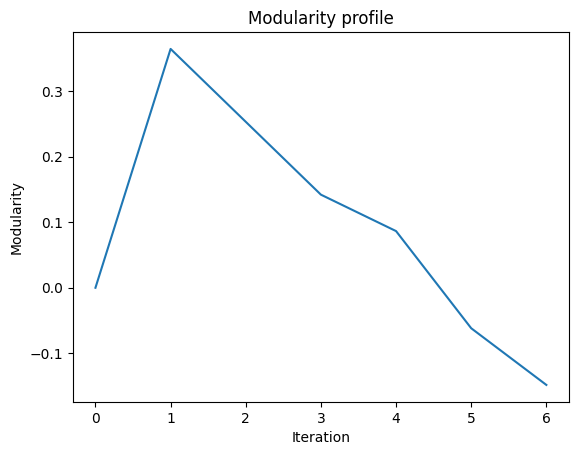

In [30]:
# LEAVE AS-IS

run_girvan_newman(g)

Partition [{'RIC OLIE', 'YODA', 'BAIL ORGANA', 'MACE WINDU', 'CAPTAIN PANAKA', 'POGGLE', 'QUI-GON', 'WATTO', 'LANDO', 'MON MOTHMA', 'WEDGE', 'BALA-TIK', 'SIO BIBBLE', 'BIGGS', 'BOSS NASS', 'LEIA', 'POE', 'LUKE', 'BOBA FETT', 'R2-D2', 'ADMIRAL STATURA', 'FINN', 'JABBA', 'REY', 'COUNT DOOKU', 'KI-ADI-MUNDI', 'SEBULBA', 'OBI-WAN', 'RED LEADER', 'KITSTER', 'SENATOR ASK AAK', 'HAN', 'SNAP', 'CLIEGG', 'NUTE GUNRAY', 'MAZ', 'ADMIRAL ACKBAR', 'SUN RIT', 'EMPEROR', 'BB-8', 'DARTH VADER', 'CAPTAIN TYPHO', 'CHEWBACCA', 'RABE', 'SHMI', 'CAPTAIN PHASMA', 'JAR JAR', 'PADME', 'BERU', 'OWEN', 'KYLO REN', 'C-3PO'}]
Modularity: 0.0000

Partition [{'RIC OLIE', 'YODA', 'BAIL ORGANA', 'MACE WINDU', 'CAPTAIN PANAKA', 'POGGLE', 'QUI-GON', 'WATTO', 'SIO BIBBLE', 'BOSS NASS', 'R2-D2', 'JABBA', 'COUNT DOOKU', 'KI-ADI-MUNDI', 'SEBULBA', 'OBI-WAN', 'KITSTER', 'SENATOR ASK AAK', 'CLIEGG', 'NUTE GUNRAY', 'SUN RIT', 'EMPEROR', 'DARTH VADER', 'CAPTAIN TYPHO', 'RABE', 'SHMI', 'JAR JAR', 'PADME', 'BERU', 'OWEN', 'C-3PO

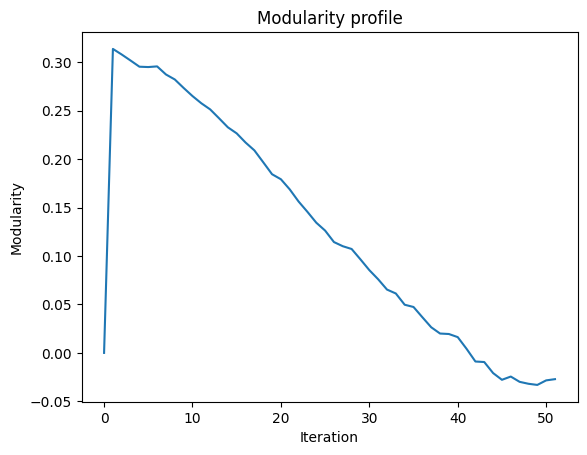

In [31]:
# LEAVE AS-IS
run_girvan_newman(swcore)

The modularity profiles show how well a graph is divided into communities at each iteration of the Girvan-Newman algorithm. Modularity increases initially, peaking when the graph is optimally partitioned into well-defined communities, and decreases as over-partitioning occurs. The partition corresponding to the highest modularity should be chosen, as it represents the best balance between internal density and external sparsity of connections. 

In [32]:
def run_girvan_newman_modularity(g):
    partitions = girvan_newman(g)
    best_partition = None
    best_modularity = -1.0
    
    for partition in partitions:
        m = modularity(g, partition)
        if m > best_modularity:
            best_modularity = m
            best_partition = partition
    
    return best_partition

The best partition has modularity 0.3137 and 2 communities


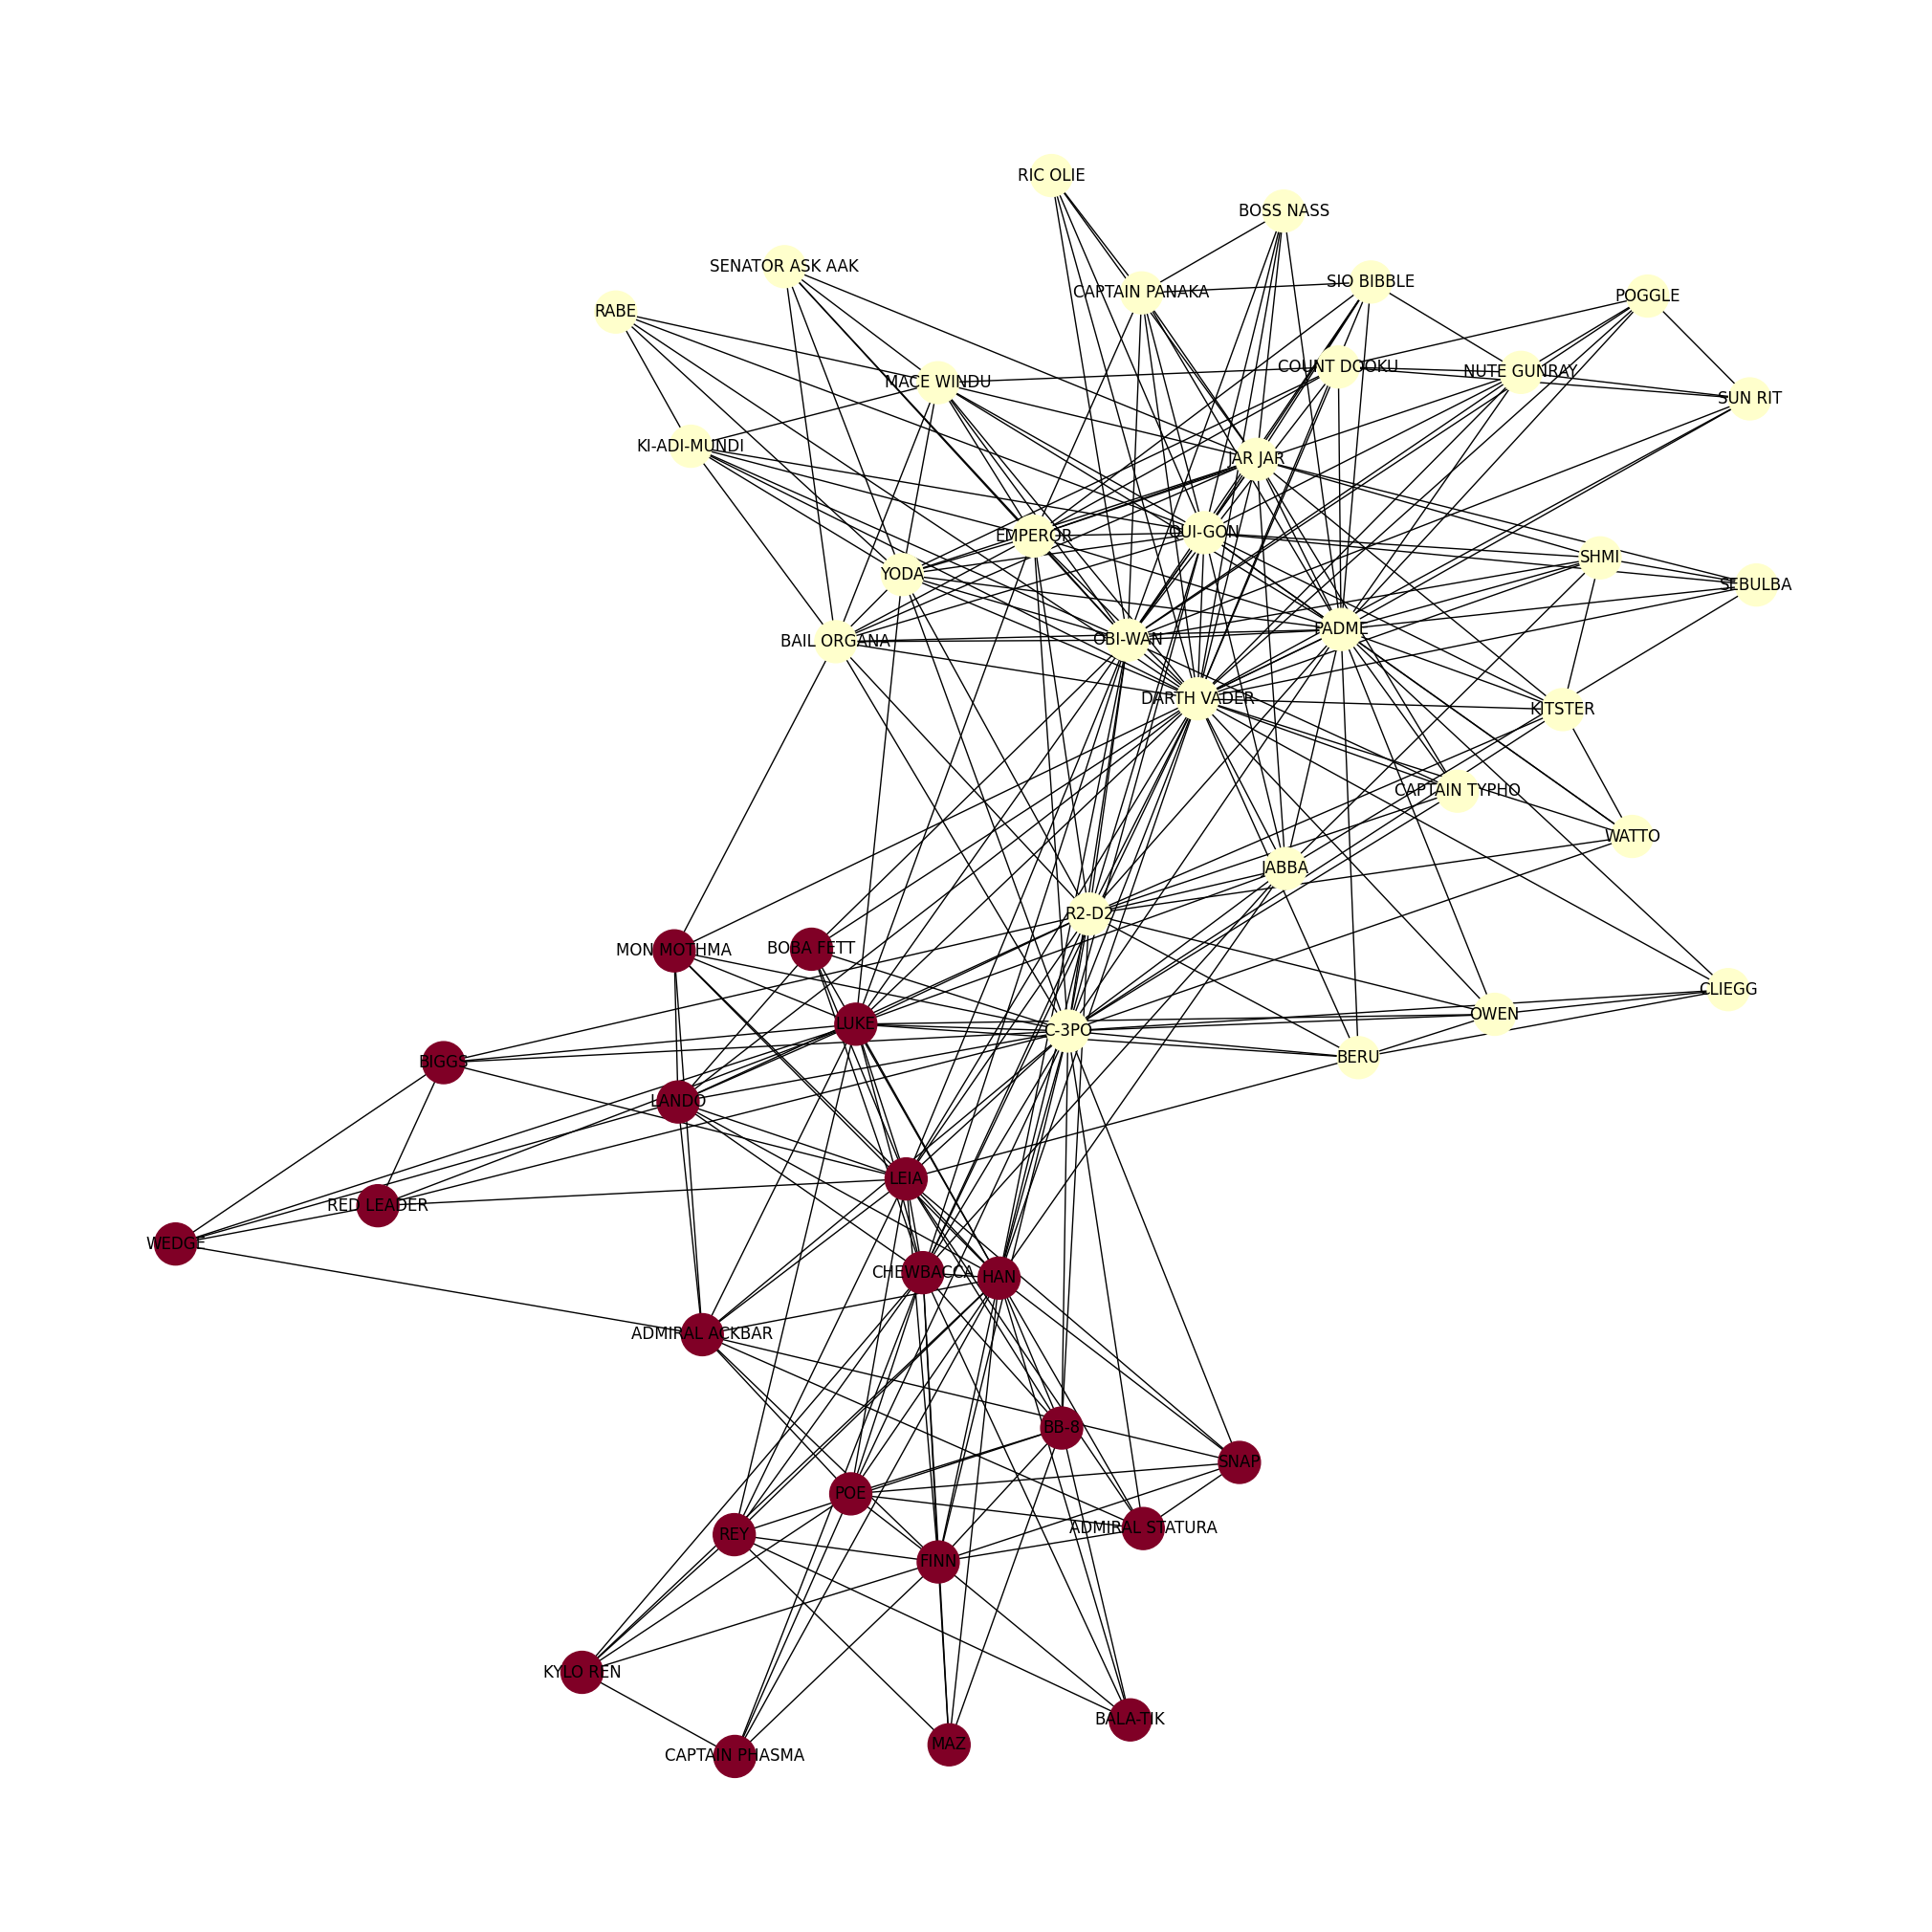

In [33]:
# LEAVE AS-IS

partition = run_girvan_newman_modularity(swcore)
print("The best partition has modularity %.4f and %d communities" % (modularity(swcore, partition), len(partition)))
plot_graph(swcore, partition=partition)

The red node community includes characters like Luke, Leia, Han, and Darth Vader, which are central to the main Star Wars storyline for the final movies. The yellow nodes contain characters such as Yoda, Obi-Wan, or Padme, which have a more crucial role in the first movies. Some central nodes like R2-D2 have a crucial role in the two trilogies, so they have a higher degree that connects the two partitionings. I see that mostly it is consistent with the other partition; however, regarding the characters from the third trilogy (the new Disney one with Kylo Ren and Rey), they are regarded as very connected in the other partitions even though they do not have such a crucial role in the movies as a whole .

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>